# 02.4 · Gradient descent: walking downhill

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/02-regression/04-gradient-descent/lesson.ipynb)

Read the [README](README.md) first and do the three hand iterations. This notebook checks them, runs thousands more, draws the bowl and the path, and shows the two ways it breaks (learning rate, unscaled features).

## 1. The three hand iterations, checked

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd
five = pd.read_csv(data_path("shopwave_visits_spend_5.csv"))
five

,customer_id,visits_last_month,spend_next_month
0,C001,2,50
1,C002,4,80
2,C003,6,90
3,C004,8,130
4,C005,10,150


In [2]:
import numpy as np
x = five["visits_last_month"].to_numpy(dtype=float)
y = five["spend_next_month"].to_numpy(dtype=float)

m, c, alpha = 0.0, 0.0, 0.01
for it in range(1, 4):
    y_hat = m * x + c
    resid = y - y_hat
    loss = (resid**2).mean()
    grad_m = -2 * (x * resid).mean()
    grad_c = -2 * resid.mean()
    print(f"iteration {it}: m={m:.2f} c={c:.2f}  loss={loss:.1f}  "
          f"∂J/∂m={grad_m:.2f} ∂J/∂c={grad_c:.2f}  →  m={m - alpha*grad_m:.2f} c={c - alpha*grad_c:.2f}")
    m -= alpha * grad_m
    c -= alpha * grad_c

iteration 1: m=0.00 c=0.00  loss=11280.0  ∂J/∂m=-1400.00 ∂J/∂c=-200.00  →  m=14.00 c=2.00
iteration 2: m=14.00 c=2.00  loss=244.0  ∂J/∂m=-144.00 ∂J/∂c=-28.00  →  m=15.44 c=2.28
iteration 3: m=15.44 c=2.28  loss=125.0  ∂J/∂m=-13.92 ∂J/∂c=-10.16  →  m=15.58 c=2.38


Same numbers as your paper. Now the full walk.

## 2. Five thousand steps

In [3]:
def gradient_descent(x, y, alpha, steps, m=0.0, c=0.0):
    """Return the path of (m, c, loss) for `steps` iterations."""
    path = []
    for _ in range(steps):
        y_hat = m * x + c
        resid = y - y_hat
        loss = (resid**2).mean()
        path.append((m, c, loss))
        grad_m = -2 * (x * resid).mean()
        grad_c = -2 * resid.mean()
        m -= alpha * grad_m
        c -= alpha * grad_c
    return pd.DataFrame(path, columns=["m", "c", "loss"])

path = gradient_descent(x, y, alpha=0.01, steps=5000)
print(path.iloc[[0, 1, 2, 10, 100, 1000, 4999]].round(3))

           m       c       loss
0      0.000   0.000  11280.000
1     14.000   2.000    244.000
2     15.440   2.280    124.955
10    15.520   2.943    118.462
100   14.689   9.013     76.473
1000  12.588  24.360     30.074
4999  12.500  25.000     30.000


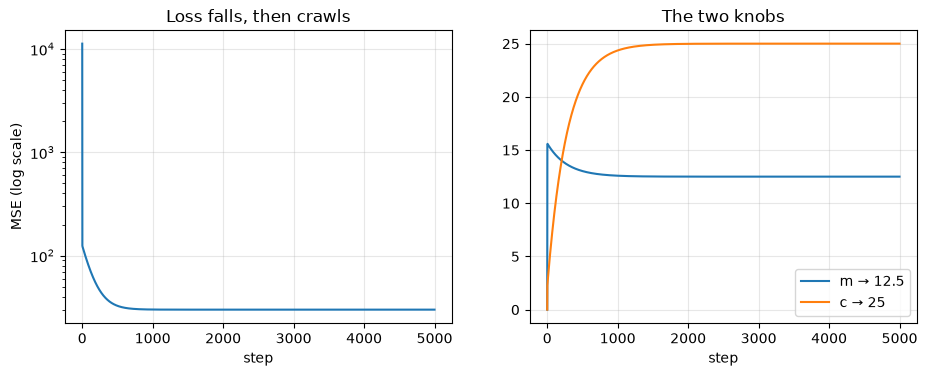

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(path["loss"]); axes[0].set(yscale="log", xlabel="step", ylabel="MSE (log scale)", title="Loss falls, then crawls")
axes[1].plot(path["m"], label="m → 12.5"); axes[1].plot(path["c"], label="c → 25")
axes[1].set(xlabel="step", title="The two knobs"); axes[1].legend()
for ax in axes: ax.grid(alpha=.3)
plt.show()

`m` overshoots to 15.6 in three steps and then takes thousands of steps to slide back to 12.5 while `c` climbs to 25. The loss drops 99% in the first ten steps and spends the remaining 4,990 polishing the last 1%.

## 3. The bowl and the path

The loss as a function of `(m, c)` is a bowl. Contour lines are "same height". The path walks down the steep direction first (m), then along the shallow valley floor (c).

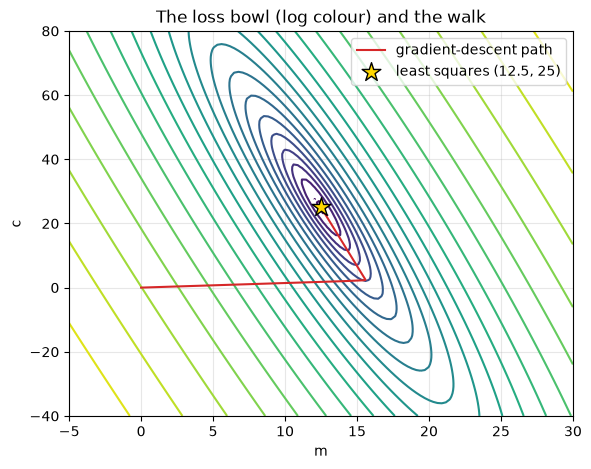

In [5]:
M, C = np.meshgrid(np.linspace(-5, 30, 120), np.linspace(-40, 80, 120))
J = np.mean([(yi - (M * xi + C))**2 for xi, yi in zip(x, y)], axis=0)

plt.figure(figsize=(6.5, 5))
plt.contour(M, C, np.log10(J), levels=25, cmap="viridis")
plt.plot(path["m"], path["c"], color="tab:red", linewidth=1.5, label="gradient-descent path")
plt.scatter([12.5], [25], marker="*", s=200, color="gold", edgecolor="k", zorder=5, label="least squares (12.5, 25)")
plt.xlabel("m"); plt.ylabel("c"); plt.title("The loss bowl (log colour) and the walk"); plt.legend(); plt.grid(alpha=.3)
plt.show()

The valley is long and narrow because `m` and `c` live on very different scales (changing `m` by 1 moves predictions by up to 10; changing `c` by 1 moves them by 1). Section 6 fixes this.

## 4. Learning rate: too small, right, too big

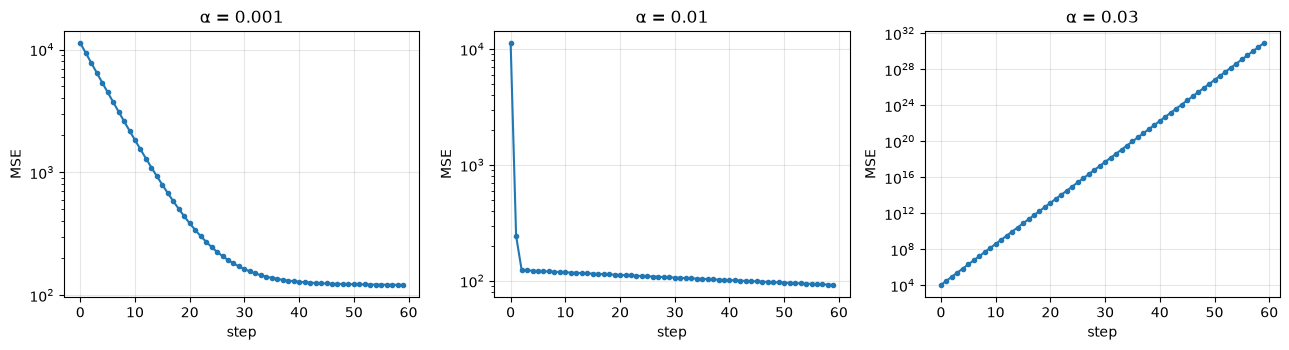

α=0.001: loss after 60 steps = 121.3
α=0.01: loss after 60 steps = 92.31
α=0.03: loss after 60 steps = 8.253e+30


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, alpha in zip(axes, [0.001, 0.01, 0.03]):
    p = gradient_descent(x, y, alpha=alpha, steps=60)
    ax.plot(p["loss"], marker=".")
    ax.set(title=f"α = {alpha}", xlabel="step", ylabel="MSE", yscale="log"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
for alpha in [0.001, 0.01, 0.03]:
    p = gradient_descent(x, y, alpha=alpha, steps=60)
    print(f"α={alpha}: loss after 60 steps = {p['loss'].iloc[-1]:.4g}")

- **0.001**: converging, but after 60 steps it is still far away.
- **0.01**: well on its way (and, as section 2 showed, it arrives).
- **0.03**: each step overshoots further than the last; the loss *grows* and reaches astronomical numbers. This is what "training diverged" looks like in every ML framework.

## 5. Where the formula comes from (optional)

The derivatives in the README are two lines of the chain rule. If you have never differentiated, skip this; the intuition in section 1 of the README is enough for the whole course.

With $J = \frac{1}{n}\sum (y_i - m x_i - c)^2$, differentiate each squared term: the derivative of $u^2$ is $2u \cdot u'$, and for $u = y_i - m x_i - c$ we have $\partial u/\partial m = -x_i$ and $\partial u/\partial c = -1$. So

$\partial J/\partial m = \frac{1}{n}\sum 2(y_i - \hat y_i)(-x_i) = -\frac{2}{n}\sum x_i (y_i - \hat y_i)$, and likewise for $c$ with $-1$ in place of $-x_i$.

## 6. The real data, and why scaling matters

Past spend → next-quarter spend on the 3,317 customers. scikit-learn (02.3) found slope 0.48, intercept 6. Try gradient descent on the raw column.

In [7]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()


def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")


cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(
    orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
    products=("StockCode", "nunique"), items=("Quantity", "sum"),
    first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"),
    country=("Country", "first"))
cust["avg_order"] = cust["spend"] / cust["orders"]
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
cust["spend_next_quarter"] = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust = cust.drop(columns=["first_order", "last_order"])
print(f"{len(cust):,} customers; features from before {cutoff.date()}, target = spend Sep–Nov 2011")
cust.head()

(541910, 8)
541,910 rows → 392,693 after cleaning


3,317 customers; features from before 2011-09-01, target = spend Sep–Nov 2011


,orders,spend,products,items,country,avg_order,tenure_days,days_since_last,spend_next_quarter
Customer ID,,,,,,,,,
12346,1,77183.60,1,74215,United Kingdom,77183.600000,225,225,0.00
12347,5,2790.86,82,1590,Iceland,558.172000,267,29,1294.32
12348,3,1487.24,22,2124,Finland,495.746667,258,148,310.00
12350,1,334.40,17,197,Norway,334.400000,210,210,0.00
12352,5,1561.81,26,254,Norway,312.362000,196,162,944.23


In [8]:
xr = cust["spend"].to_numpy(dtype=float)
yr = cust["spend_next_quarter"].to_numpy(dtype=float)
print(f"x ranges from £{xr.min():.0f} to £{xr.max():,.0f}; std £{xr.std():,.0f}")
for alpha in [1e-6, 1e-8, 1e-10]:
    with np.errstate(over="ignore", invalid="ignore"):      # let the divergence show as nan, not warnings
        p = gradient_descent(xr, yr, alpha=alpha, steps=200)
    print(f"α={alpha:g}: final m={p['m'].iloc[-1]:.4g}  c={p['c'].iloc[-1]:.4g}  loss={p['loss'].iloc[-1]:.4g}")

x ranges from £3 to £176,356; std £5,973
α=1e-06: final m=nan  c=nan  loss=nan
α=1e-08: final m=0.5345  c=-0.0002423  loss=5.114e+06
α=1e-10: final m=0.4182  c=1.463e-05  loss=5.631e+06


With raw pounds, a learning rate small enough to keep `m` from exploding is far too small for `c` to move at all. There is no single α that works.

**The fix:** put `x` on a unit scale (subtract the mean, divide by the standard deviation). Then both knobs have similar-sized gradients and α = 0.1 works in a few hundred steps. Convert the slope back afterwards.

In [9]:
x_scaled = (xr - xr.mean()) / xr.std()
p = gradient_descent(x_scaled, yr, alpha=0.1, steps=300)
m_s, c_s = p["m"].iloc[-1], p["c"].iloc[-1]
m_orig = m_s / xr.std()                   # undo the scaling
c_orig = c_s - m_orig * xr.mean()
print(f"gradient descent (scaled): slope {m_orig:.4f}, intercept {c_orig:.2f}, loss {p['loss'].iloc[-1]:,.0f}")

from sklearn.linear_model import LinearRegression
lr = LinearRegression().fit(cust[["spend"]], yr)
print(f"scikit-learn:              slope {lr.coef_[0]:.4f}, intercept {lr.intercept_:.2f}")

gradient descent (scaled): slope 0.5375, intercept -71.05, loss 5,109,499


scikit-learn:              slope 0.5375, intercept -71.05


Same line. Scaling is not cosmetic: for anything trained by gradient descent it is the difference between working and not working. Lesson 04.5 makes it routine.

## Quiz answers

1. **Uphill.** That is why we subtract it.
2. The gradient points towards *higher* loss; we want lower, so we step against it.
3. Too large: overshoot, loss grows, divergence to `inf`/`nan`. Too small: converges correctly but needs far more steps.
4. The gradient for $m$ is weighted by $x$ (values 2–10), so it is several times larger than the gradient for $c$; same learning rate, bigger step.
5. Almost no other model has a closed-form formula. Gradient descent works for any model whose loss you can differentiate, which is nearly all of them, including neural networks.

**Next:** [02.5 Many features](../05-multiple-regression/)